# Building a multilingual corpus on the Imperial Russian Theatre

### Institutional Books + DuckDB, from imperfect catalogue metadata

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PULdischo/discho-blog/blob/main/src/assets/notebooks/institutional-books-duckdb.ipynb)

[Institutional Books 1.0](https://huggingface.co/datasets/institutional/institutional-books-hl)
is 983,004 public-domain books digitised from Harvard Library — about **947 GB** of OCR
text spread across 9,831 Parquet files. Almost no research question needs all of it.

This is the **applied** companion to the gentle
[Yiddish walkthrough](https://github.com/PULdischo/discho-blog/blob/main/src/assets/notebooks/institutional-books-yiddish.ipynb).
That post fixed the core vocabulary — *metadata* vs. *full text*, *barcode_src*, *shards*,
*manifest* — on the simplest possible question (one language column). This one puts the
same pattern to work on a harder one, where the filter is uncertain and the answer has to
be checked.

**The research question:** collect writing about the **Imperial Russian theatres during
the Silver Age (roughly 1890–1917)** — the ballet at the Mariinsky and its composers,
ballet masters and dancers; the theatres as an institution; the critics and historians
who chronicled them (Pleshcheyev, Skalkovsky, Khudekov); and the official **Yearbook of
the Imperial Theatres** (*Ежегодникъ Императорскихъ театровъ*). The literature is in
Russian, French, German and English at least, so we search across scripts.

The workflow, unchanged from the gentle version:

1. **Filter** the small (306 MB, ungated) metadata with a broad query — title, subject
   and author, across languages.
2. **Fetch** the full text for just the candidate books.
3. **Verify** which candidates are genuinely on-topic (a keyword heuristic, then an
   open-weights decision model that runs on Colab).
4. **Publish** a reproducible *corpus manifest* so others can rebuild the exact selection.

> **Licence.** The metadata is open. The full-text datasets are released under the
> [IDI Terms of Use](https://institutionaldatainitiative.org/) — **noncommercial use
> only, and no redistribution of the text or of derivatives that "substantially
> reproduce" it.** That constraint shapes step 4: we publish a manifest of identifiers
> and our own annotations, not the text.

## 0. Setup

`duckdb` does the heavy lifting. Its `httpfs` extension reads a Parquet file over
HTTPS with *range requests* — it fetches the file footer, works out which row groups
and columns your query touches, and downloads only those bytes.

In [41]:
!pip -q install "duckdb>=1.1.0" huggingface_hub datasets pandas matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import duckdb, re, json, os
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()
con.sql("INSTALL httpfs; LOAD httpfs;")
con.sql("SET enable_progress_bar = false;")   # avoid blank/black query progress bars in the notebook
con.sql("SELECT version() AS duckdb_version").show()


┌────────────────┐
│ duckdb_version │
│    varchar     │
├────────────────┤
│ v1.5.5         │
└────────────────┘



## 1. Get the metadata (once) and query it locally

The metadata lives in a **single ~306 MB Parquet file** and is **not gated** — no token
needed. We *could* point DuckDB straight at the `hf://` URL and let `httpfs` fetch only
the bytes each query touches. In practice, anonymous range requests to the Hub get
**rate-limited (HTTP 429)** once a notebook fires enough of them — and every cell below
re-queries this file. So pull it **once** with `hf_hub_download` (which caches it and
backs off on 429), then query the local copy. The range-request trick still earns its
keep in §3, against the 947 GB full-text dataset where downloading everything is not an
option.

In [3]:
# Download the metadata Parquet once (cached under ~/.cache/huggingface, retried on 429),
# then hand DuckDB the local path. Anonymous hf:// range requests work too, but the Hub
# rate-limits them (HTTP 429) once a notebook issues enough - and we query this a dozen
# times below.
from huggingface_hub import hf_hub_download

META = hf_hub_download(
    "institutional/institutional-books-hl-metadata",
    "data/train-00000-of-00001.parquet",
    repo_type="dataset",
)
print(META)

# The schema. Note that text is NOT here - only in the 947 GB dataset.
con.sql(f"DESCRIBE SELECT * FROM '{META}'").df()

/home/apjanco/.cache/huggingface/hub/datasets--institutional--institutional-books-hl-metadata/snapshots/e0c0b860482e49cced246c5cd7c0d22ac8a86040/data/train-00000-of-00001.parquet


,column_name,column_type,null,key,default,extra
0,barcode_src,VARCHAR,YES,None,None,None
1,title_src,VARCHAR,YES,None,None,None
2,author_src,VARCHAR,YES,None,None,None
3,date1_src,VARCHAR,YES,None,None,None
4,date2_src,VARCHAR,YES,None,None,None
5,date_types_src,VARCHAR,YES,None,None,None
6,page_count_src,INTEGER,YES,None,None,None
7,token_count_o200k_base_gen,INTEGER,YES,None,None,None
8,language_src,VARCHAR,YES,None,None,None
9,language_gen,VARCHAR,YES,None,None,None


In [4]:
con.sql(f"SELECT count(*) AS n_books FROM '{META}'").show()

con.sql(f"""
    SELECT barcode_src, title_src, author_src, date1_src,
           language_src, language_gen, topic_or_subject_src
    FROM '{META}'
    LIMIT 5
""").show()

┌─────────┐
│ n_books │
│  int64  │
├─────────┤
│  983004 │
└─────────┘

┌────────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┬───────────────────────────┬───────────┬──────────────┬──────────────┬─────────────────────────────────────────────┐
│  barcode_src   │                                                                            title_src                                                                             │        author_src         │ date1_src │ language_src │ language_gen │            topic_or_subject_src             │
│    varchar     │                                                                             varchar                                                                              │          varchar          │  varchar  │   varchar    │   varchar    │                   varchar                   │
├────────────────┼───────────────

That ran against the local file — instant, and zero Hub requests. DuckDB still reads
only the columns and row groups each query needs; against the 947 GB full-text dataset
in §3 that same column/row-group pruning happens over HTTP range requests, which is what
makes step 2 possible at all.

Key columns for selection work:

| column | what it is |
|---|---|
| `barcode_src` | the join key to the full-text dataset |
| `title_src`, `author_src` | from the catalogue record |
| `language_src` | language in the catalogue record (ISO 639-3) |
| `language_gen` | language **detected from the OCR text** (ISO 639-3) |
| `language_distribution_gen` | `{language[], proportion[]}` — for multilingual volumes |
| `topic_or_subject_src` | Library of Congress subject terms, comma-joined (often null) |
| `date1_src` | publication year as a string — **messy** (`"18uu"`, `""`, ranges) |
| `token_count_o200k_base_gen` | size of the book in tokens — handy for estimating download size |
| `ocr_score_gen`, `ocr_score_src` | OCR quality (higher is better) |
| `likely_duplicates_barcodes_gen` | barcodes of near-duplicate scans |

## 2. Know your corpus

### 2a. Language census — one `GROUP BY` over 983k books

In [5]:
langs = con.sql(f"""
    SELECT language_gen,
           count(*)                          AS n_books,
           sum(token_count_o200k_base_gen)   AS tokens
    FROM '{META}'
    WHERE language_gen IS NOT NULL
    GROUP BY language_gen
    ORDER BY n_books DESC
""").df()

print(f"{len(langs)} distinct detected languages")
langs.head(20)

250 distinct detected languages


,language_gen,n_books,tokens
0,eng,487353,1.107978e+11
1,deu,157776,4.379342e+10
2,fra,135872,3.388674e+10
3,ita,46074,9.918975e+09
4,spa,28836,5.530821e+09
5,lat,21640,6.778434e+09
6,rus,15115,5.733377e+09
7,nld,12682,3.067559e+09
8,dan,7899,2.047159e+09
9,por,7158,1.514410e+09


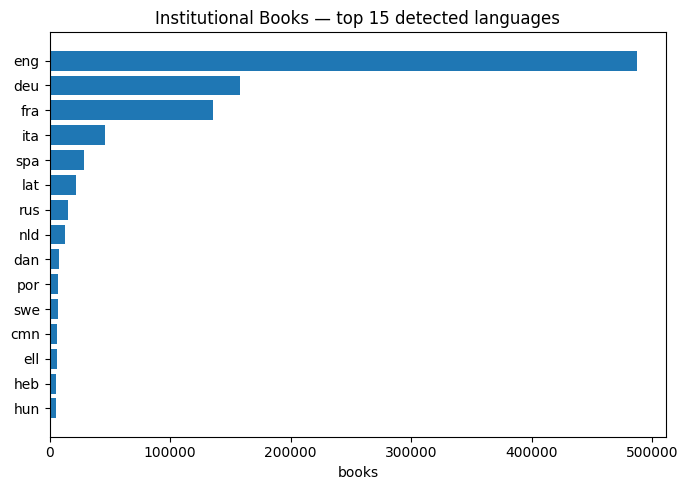

In [6]:
top = langs.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.language_gen, top.n_books)
ax.set_xlabel("books")
ax.set_title("Institutional Books — top 15 detected languages")
fig.tight_layout()
fig.savefig("language-census.png", dpi=120)
plt.show()

### 2b. The catalogue and the text disagree

`language_src` comes from a human cataloguer decades ago; `language_gen` comes from
running language detection over the OCR. Comparing them is a quick data-quality check —
and a warning that "language" is not a clean single value for many volumes.

In [7]:
disagree = con.sql(f"""
    SELECT
        count(*) FILTER (WHERE language_src IS DISTINCT FROM language_gen) AS n_disagree,
        count(*)                                                          AS n_total
    FROM '{META}'
""").df()
pct = 100 * disagree.n_disagree[0] / disagree.n_total[0]
print(f"{disagree.n_disagree[0]:,} of {disagree.n_total[0]:,} books "
      f"({pct:.1f}%) have language_src != language_gen")

con.sql(f"""
    SELECT language_src, language_gen, count(*) AS n
    FROM '{META}'
    WHERE language_src IS DISTINCT FROM language_gen
    GROUP BY 1, 2
    ORDER BY n DESC
    LIMIT 15
""").show()

54,214 of 983,004 books (5.5%) have language_src != language_gen
┌──────────────┬──────────────┬───────┐
│ language_src │ language_gen │   n   │
│   varchar    │   varchar    │ int64 │
├──────────────┼──────────────┼───────┤
│ zho          │ cmn          │  5926 │
│ ara          │ arb          │  2962 │
│ eng          │ fra          │  2540 │
│ eng          │ deu          │  2127 │
│ nor          │ dan          │  2096 │
│ lat          │ ell          │  1646 │
│ deu          │ lat          │  1329 │
│ grc          │ ell          │  1172 │
│ eng          │ lat          │  1036 │
│ ota          │ prs          │   904 │
│ lat          │ eng          │   873 │
│ deu          │ fra          │   751 │
│ lat          │ deu          │   734 │
│ fra          │ lat          │   718 │
│ yid          │ ydd          │   671 │
└──────────────┴──────────────┴───────┘
  15 rows                   3 columns



### 2c. When were the books in this corpus published?

`date1_src` is a MARC date field: mostly 4-digit years, but with `"18uu"`, empty
strings, and the odd out-of-range value. Clean it before plotting.

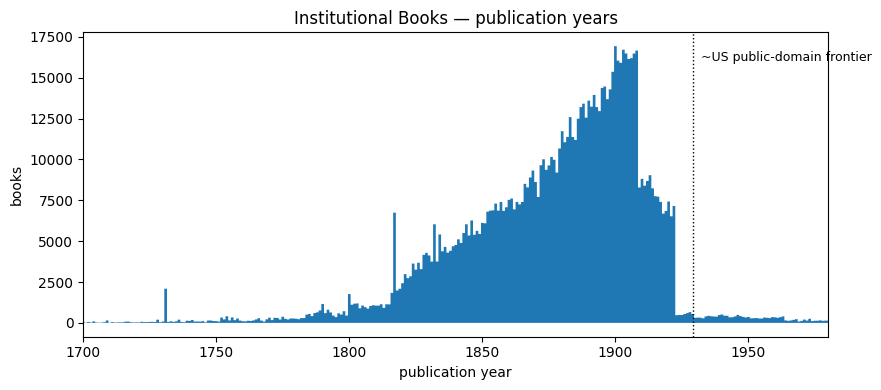

In [8]:
dates = con.sql(f"""
    SELECT year, count(*) AS n_books
    FROM (
        SELECT TRY_CAST(date1_src AS INTEGER) AS year
        FROM '{META}'
        WHERE regexp_full_match(date1_src, '\\d{{4}}')
    )
    WHERE year BETWEEN 1450 AND 2025
    GROUP BY year
    ORDER BY year
""").df()

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(dates.year, dates.n_books, step="mid")
ax.set_xlim(1700, 1980)
ax.set_xlabel("publication year")
ax.set_ylabel("books")
ax.set_title("Institutional Books — publication years")
ax.axvline(1929, color="black", ls=":", lw=1)
ax.text(1929, ax.get_ylim()[1] * 0.9, "  ~US public-domain frontier", fontsize=9)
fig.tight_layout()
fig.savefig("corpus-dates.png", dpi=120)
plt.show()

The mass of the collection sits in the **long 19th century up to the late 1920s** —
the public-domain frontier. Keep that in mind when you pick a topic: if the scholarly
vocabulary you would search for was coined *after* ~1930, the corpus can't help you.
The Imperial theatres in their Silver Age (roughly 1890–1917) sit right inside the
window, and the Yearbook of the Imperial Theatres ran until 1915.

## 3. Authenticate, then fetch the text

The full-text dataset is **gated** (auto-approved). One-time steps:

1. Log in to Hugging Face and open
   [institutional/institutional-books-hl](https://huggingface.co/datasets/institutional/institutional-books-hl).
2. Accept the IDI early-access terms (instant).
3. Create a **read** token.

Then authenticate this session:

In [53]:
from huggingface_hub import notebook_login
notebook_login()

In [54]:
# Let DuckDB pick up the cached HF token for hf:// range requests.
con.sql("DROP SECRET IF EXISTS hf;")
con.sql("CREATE SECRET hf (TYPE huggingface, PROVIDER credential_chain);")

┌─────────┐
│ Success │
│ boolean │
├─────────┤
│ true    │
└─────────┘

### 3a. The naive fetch — and why it's slow

```sql
SELECT ... FROM 'hf://.../institutional-books-hl/data/train-*.parquet'
WHERE barcode_src IN (...)
```

That glob works, but before DuckDB can prune anything it has to read the **footer of
all 9,831 shards** — thousands of HTTP requests. It finishes in a few minutes and still
only downloads the row groups that match, but we can do better if the shards line up
with the metadata.

### 3b. Do the shards line up with the metadata row order?

If metadata row *i* is book *i* of shard `i // rows_per_shard`, we can compute exactly
which shards to query and skip the 9,831-footer scan entirely.

In [12]:
HL_REPO  = "institutional/institutional-books-hl"
N_SHARDS = 9831

def shard_name(i):
    return f"data/train-{i:05d}-of-0{N_SHARDS}.parquet"

from huggingface_hub import hf_hub_download

con.sql("SET threads TO 1;")   # so row order is the file's physical order

# Pull shard 0 and compare its barcodes to the first N metadata rows, in order.
shard0 = hf_hub_download(HL_REPO, shard_name(0), repo_type="dataset")
s0 = con.sql(f"SELECT barcode_src FROM read_parquet('{shard0}')").df().barcode_src.tolist()
ROWS_PER_SHARD = len(s0)
print("rows in shard 0:", ROWS_PER_SHARD)

meta_head = con.sql(
    f"SELECT barcode_src FROM '{META}' LIMIT {ROWS_PER_SHARD}"
).df().barcode_src.tolist()

aligned = s0 == meta_head
print("shard 0 == metadata rows 0..N, in order:", aligned)

rows in shard 0: 100
shard 0 == metadata rows 0..N, in order: True


**If `aligned` is `True`** we can compute the exact set of shards that hold our books
and touch only those. **If it is `False`** we fall back to sweeping all 9,831 shards —
slower (~2 h) but always correct. Either way the fetch below is the *same* function.

### 3c. Concurrent shard fetch

Rather than `hf_hub_download`-ing whole shards and filtering locally, we run a
`WHERE barcode_src IN (...)` query against each shard **over `hf://`** — DuckDB pulls
only the row groups it needs and nothing lands on disk (which matters when the full
cache would be ~947 GB). Three practical details, all borrowed from a batch script that
did the full sweep in production:

* **Concurrency.** Per-file round-trip latency, not bandwidth, is the ceiling
  (~1.3 shards/s), so we fetch shards from a thread pool — one DuckDB connection per
  worker, each with its own HF secret and `threads=1`.
* **Retries.** Each shard retries a few times with backoff; a stray 429 or dropped
  connection over a long run no longer kills everything.
* **Early exit.** The sweep stops as soon as every requested barcode has been found.

> The full-text repo id used here is `institutional/institutional-books-hl`. Some tooling
> in the wild refers to `institutional/institutional-books-1.0` — check which one is live
> for your account.

In [ ]:
import threading, time
from concurrent.futures import ThreadPoolExecutor, as_completed

HL_URL = f"hf://datasets/{HL_REPO}/data/train-{{:05d}}-of-0{N_SHARDS}.parquet"
_tl = threading.local()

# DuckDB shows a per-connection query progress bar; under many worker threads it renders
# as stacked blank/black bars in the notebook. Turn it off — our own print() is the meter.
con.execute("SET enable_progress_bar = false;")


def _worker_con():
    """One DuckDB connection per worker thread, each with its own HF secret."""
    if not hasattr(_tl, "con"):
        c = duckdb.connect()
        c.execute("INSTALL httpfs; LOAD httpfs;")
        c.execute("CREATE SECRET hf (TYPE huggingface, PROVIDER credential_chain);")
        c.execute("SET threads TO 1;")
        c.execute("SET enable_progress_bar = false;")   # no blank progress bars
        _tl.con = c
    return _tl.con


def _shards_for(barcodes):
    """Exact shard list when the §3b alignment holds, else every shard."""
    if not aligned:
        return list(range(N_SHARDS))
    con.execute("SET threads TO 1;")   # row_number() must follow physical order
    bc = "', '".join(barcodes)
    return con.sql(f"""
        WITH numbered AS (
            SELECT barcode_src, row_number() OVER () - 1 AS ridx FROM '{META}'
        )
        SELECT DISTINCT (ridx // {ROWS_PER_SHARD})::INT AS shard
        FROM numbered WHERE barcode_src IN ('{bc}')
        ORDER BY shard
    """).df().shard.tolist()


def fetch_text(barcodes, concurrency=16, retries=4):
    barcodes = list(barcodes)
    want = set(barcodes)
    bc_sql = "', '".join(barcodes)
    shards = _shards_for(barcodes)
    print(f"{len(barcodes)} books -> {len(shards)} shard(s) "
          f"{'(aligned: exact set)' if aligned else '(full sweep, ~2h)'}", flush=True)

    def one(idx):
        q = f"""
            SELECT barcode_src, title_src, language_gen,
                   array_to_string(text_by_page_src, chr(10)) AS text_src,
                   CASE WHEN len(text_by_page_gen) > 0
                        THEN array_to_string(text_by_page_gen, chr(10)) END AS text_gen
            FROM read_parquet('{HL_URL.format(idx)}')
            WHERE barcode_src IN ('{bc_sql}')
        """
        for attempt in range(retries):
            try:
                return _worker_con().execute(q).fetchdf()
            except Exception as e:
                if attempt == retries - 1:
                    print(f"  shard {idx} gave up: {e}", flush=True)
                    return None
                time.sleep(3 * (attempt + 1))

    out, found, done = [], set(), 0
    with ThreadPoolExecutor(max_workers=concurrency) as ex:
        futs = {ex.submit(one, i): i for i in shards}
        for f in as_completed(futs):
            done += 1
            r = f.result()
            if r is not None and len(r):
                out.append(r)
                found |= set(r.barcode_src)
            if done % 200 == 0 or found == want:
                print(f"  {done}/{len(shards)} shards | {len(found)}/{len(want)} books",
                      flush=True)
            if found == want:                       # every barcode accounted for
                for fut in futs:
                    fut.cancel()
                break

    cols = ["barcode_src", "title_src", "language_gen", "text_src", "text_gen"]
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=cols)


## 4. Cast a wide net over the metadata

We have no clean single-column filter like "all Yiddish books." Instead we build a corpus
from a **broad, uncertain metadata query**, then check which matches are genuinely
on-topic.

Three signals, OR'd together:

* **title** names a composer, ballet, ballet master, dancer, one of the Imperial houses,
  or the Yearbook itself — with spelling variants and transliterations;
* **subject headings** mention ballet or theatre (the subject field carries only topical
  terms);
* **author** is one of the figures who published — the composers of the scores, or the
  critics and historians of the Imperial theatres.

We also flag the **Yearbook of the Imperial Theatres** on its own, since it is the spine
of any Imperial-theatre corpus. No language filter — that is the point.

In [ ]:
# Terms for the Imperial Russian theatres in the Silver Age: the ballet at the Mariinsky
# (its composers, works, ballet masters and dancers), the theatres as an institution, the
# critics/historians who chronicled them, and the official Yearbook of the Imperial
# Theatres. ILIKE is case-insensitive and matches substrings, so surnames/titles are given
# as stems (e.g. "Arensk" also matches "Arenski", "Аренского"). Each is covered across
# scripts: French (accented and plain), German, the common scientific/BGN transliterations,
# and Cyrillic. $$-quoting in ilike_any() keeps the apostrophes in French titles
# ("Ruses d'amour", "Nuit d'Égypte") from breaking the SQL.

# The Silver Age is the *subject* period. Start at 1890 so the earliest Yearbook volumes
# (the annual began with the 1890/91 season) fall inside the window, and keep publications
# through the 1929 public-domain frontier for contemporary reviews and near-term
# retrospectives.
START_YEAR = 1890
END_YEAR = 1929

COMPOSERS = [
    # Glazunov — Raymonda, The Seasons, Les Ruses d'amour
    "Glazunov", "Glazounov", "Glazounow", "Glasunow", "Глазунов",
    # Arensky — Egyptian Nights
    "Arensk", "Аренский",
    # Koreshchenko — The Magic Mirror
    "Koreshchenko", "Korestchenko", "Korechtchenko", "Koreščenko", "Корещенко",
    # Drigo — Imperial-ballet conductor and composer
    "Drigo", "Дриго",
]

WORKS = [
    # Raymonda (Glazunov, 1898)
    "Raymonda", "Раймонда",
    # The Magic Mirror (Koreshchenko, 1903)
    "Волшебное зеркало", "Miroir magique", "Magic Mirror",
    # Egyptian Nights / Une nuit d'Égypte (Arensky, 1900/1908)
    "Nuit d'Égypte", "Nuit d'Egypte", "Ночь в Египте", "Египетские ночи",
    # Les Ruses d'amour / The Trial of Damis (Glazunov, 1900)
    "Ruses d'amour", "Испытание Дамиса",
    # Harlequinade / Les Millions d'Arlequin (Drigo, 1900)
    "Арлекинада", "Millions d'Arlequin",
    # The Awakening of Flora (Drigo, 1894)
    "Пробуждение Флоры", "Réveil de Flore", "Reveil de Flore",
]

BALLET_MASTERS = [
    "Petipa", "Петипа",
    "Gorsky", "Gorski", "Горский",
    "Fokin", "Foquine", "Фокин",
]

DANCERS = [
    "Pavlova", "Pawlowa", "Павлова",
    "Karsavin", "Karsawin", "Карсавина",
    "Kschessinsk", "Kchessinsk", "Kshesinsk", "Krzesińsk", "Кшесинск",
    "Preobrajensk", "Preobrazhensk", "Преображенск",
    "Nijinsk", "Nizhinsk", "Нижинск",
    "Gerdt", "Гердт",
]

INSTITUTIONS = [
    "Imperial Ballet", "Imperial Theatre", "Imperial Theatres",
    "Mariinsky", "Maryinsky", "Мариинск",
    "Императорский балет", "Императорские театры", "Императорских театров",
]

# The Imperial theatres as an institution — the houses, the school, and the umbrella terms.
# Old orthography matters: these are pre-1918 books, so titles carry the hard sign (ъ) and
# і. ILIKE substrings on stems like "театр" still match "театръ"/"театровъ", and
# "Императорск" matches "Императорскій"/"Императорскихъ". The bare stems "театр" and
# "Императорск" are deliberately broad — they cast the net over Russian theatre writing in
# general; the date filter and the §5 relevance check trim the catch.
THEATERS = [
    "Императорск",                        # Imperial (stem)
    "театр",                              # theatre (stem: театръ / театра / театровъ)
    "Александринск", "Alexandrinsky", "Alexandrinski",
    "Большой театр", "Bolshoi",
    "театральное училище",                # the Imperial Theatre School
    "Imperial Theatre School", "Petersburg Theatre School",
    "Théâtres Impériaux", "Theatres Imperiaux",
]

# The Yearbook of the Imperial Theatres (Ежегодникъ Императорскихъ театровъ) — the official
# annual, and the spine of any Imperial-theatre corpus. Cover the exact old-orthography
# title, the modern spelling, the bare "Ежегодник" stem (which also matches "Ежегодникъ"),
# and the French/English renderings.
YEARBOOK = [
    "Ежегодникъ Императорскихъ театровъ",
    "Ежегодник Императорских театров",
    "Ежегодник",
    "Yearbook of the Imperial Theatres", "Year-book of the Imperial Theatres",
    "Annuaire des Théâtres Impériaux", "Annuaire des Theatres Imperiaux",
]

NAMES = COMPOSERS + WORKS + BALLET_MASTERS + DANCERS + INSTITUTIONS + THEATERS + YEARBOOK

# The human subject field (`topic_or_subject_src`) holds only *topical/genre* headings —
# it never carries personal names, so match it on the ballet/theatre topical terms that
# actually occur. "Theater" is a loose net (it catches theatre worldwide, not just Russia);
# it only adds candidates, and §5 verifies every hit against the text before we trust it.
SUBJECT_TERMS = [
    "Ballet", "Ballet dancers", "Ballets",
    "Theater", "Theaters", "Theatre", "Theatres",
    "Performing arts",
]

# Authors who actually published: the composers themselves (catalogued as authors of
# their scores and librettos), the ballet masters, and the critics/historians of the
# Imperial theatres — across scripts.
AUTHOR_TERMS = [
    "Glazunov", "Glazounov", "Глазунов",
    "Arensk", "Аренский",
    "Koreshchenko", "Корещенко",
    "Drigo", "Дриго",
    "Petipa", "Петипа",
    "Fokin", "Фокин",
    "Pleshcheyev", "Pleshcheev", "Плещеев",
    "Khudekov", "Khudekow", "Худеков",
    "Skalkovsky", "Skalkovski", "Скальковский",
    "Svetlov", "Svetloff", "Светлов",
]

def ilike_any(col, terms):
    return "(" + " OR ".join(
        f"{col} ILIKE '%' || $${t}$$ || '%'" for t in terms
    ) + ")"

query = f"""
    SELECT barcode_src, title_src, author_src, date1_src,
           language_src, language_gen, topic_or_subject_src,
           ocr_score_gen, token_count_o200k_base_gen,
           likely_duplicates_barcodes_gen,
           {ilike_any('title_src', NAMES)}                    AS hit_title,
           {ilike_any('topic_or_subject_src', SUBJECT_TERMS)} AS hit_subject,
           {ilike_any('author_src', AUTHOR_TERMS)}            AS hit_author,
           {ilike_any('title_src', YEARBOOK)}                 AS hit_yearbook
    FROM '{META}'
    WHERE (
            {ilike_any('title_src', NAMES)}
         OR {ilike_any('topic_or_subject_src', SUBJECT_TERMS)}
         OR {ilike_any('author_src', AUTHOR_TERMS)}
          )
      -- date1_src is a MARC string ("18uu", "", ranges); TRY_CAST turns junk into NULL,
      -- which drops out of the BETWEEN rather than erroring.
      AND TRY_CAST(date1_src AS INTEGER) BETWEEN {START_YEAR} AND {END_YEAR}
"""
candidates = con.sql(query).df()

# ILIKE against a NULL column yields NULL, not False — fill so the hit flags stay boolean.
for c in ["hit_title", "hit_subject", "hit_author", "hit_yearbook"]:
    candidates[c] = candidates[c].fillna(False).astype(bool)

print(f"{len(candidates)} candidate books ({START_YEAR}–{END_YEAR}); "
      f"{int(candidates.hit_yearbook.sum())} match the Yearbook of the Imperial Theatres")
candidates.groupby(["hit_title", "hit_subject", "hit_author"]).size()

44 candidate books (1895–1929)


hit_title  hit_subject  hit_author
False      False        True          22
           True         False         11
True       False        False          7
                        True           2
           True         True           2
dtype: int64

### 4a. Profile the candidates before spending bandwidth

Language spread and publication decades — both a sanity check and a figure for the
write-up.

language_gen
fra    11
rus     9
spa     7
ita     5
deu     3
eng     3
ina     3
por     2
fur     1
Name: count, dtype: int64


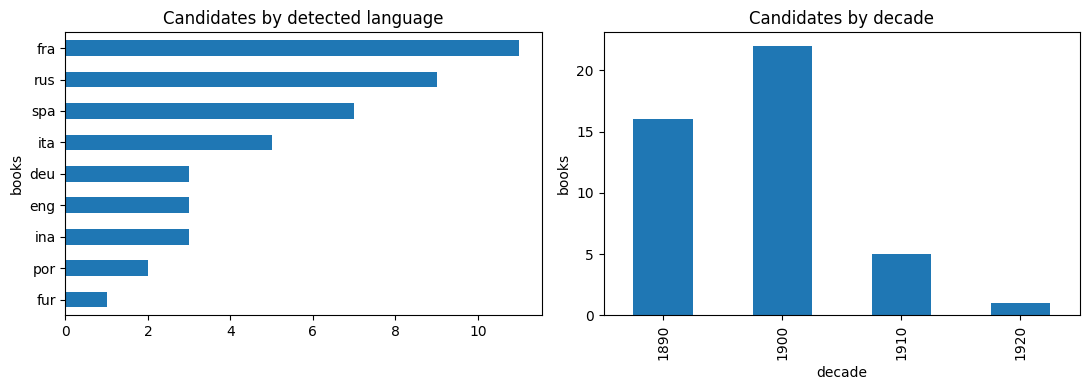

In [ ]:
by_lang = candidates.language_gen.value_counts().head(12)
print(by_lang)

cand_years = pd.to_numeric(candidates.date1_src, errors="coerce")
decade = (cand_years // 10 * 10).dropna().astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_lang.iloc[::-1].plot.barh(ax=axes[0], title="Candidates by detected language")
decade.value_counts().sort_index().plot.bar(ax=axes[1], title="Candidates by decade")
axes[1].set_xlabel("decade")
for ax in axes:
    ax.set_ylabel("books")
fig.tight_layout()
fig.savefig("imperial-theatres-profile.png", dpi=120)
plt.show()

Expect a spike in the 1910s–1920s. Rows far outside that window (an 1870s book matching
"dance") are exactly what the relevance step is for.

### 4b. Fetch the candidate text

In [16]:
cand_text = fetch_text(candidates.barcode_src.tolist())
cand_text["full_text"] = cand_text.text_gen.fillna(cand_text.text_src)
mb = cand_text.full_text.str.len().sum() / 1e6
print(f"{len(cand_text)} books, ~{mb:.0f} MB of text")

44 books -> 32 shard(s) (aligned: exact set)
  32/32 shards | 44/44 books
44 books, ~18 MB of text


## 5. Is the selection actually relevant?

A metadata match is a hypothesis. Two checks.

### 5a. Keyword heuristic — mention density

How often do the figures show up in the *body* of each book, and where did the match
originate? A book that matched only on a subject heading but never names anyone in
2,000 pages is probably mis-catalogued.

In [ ]:
name_rx = re.compile("|".join(re.escape(n) for n in NAMES), re.IGNORECASE)

def score_row(row):
    text = row.full_text or ""
    words = max(len(text.split()), 1)
    hits = len(name_rx.findall(text))
    return pd.Series({
        "n_mentions": hits,
        "mentions_per_10k_words": round(10_000 * hits / words, 2),
        "n_words": words,
    })

scored = cand_text.join(cand_text.apply(score_row, axis=1))
# Carry the catalogue fields across from the metadata: the text frame has only title and
# detected language, but §5b hands the full record to the decision model and §6 publishes
# author and subject headings in the manifest.
scored = scored.merge(
    candidates[["barcode_src", "author_src", "date1_src", "language_src",
                "topic_or_subject_src", "hit_title", "hit_subject", "hit_author"]],
    on="barcode_src", how="left",
)
scored["metadata_only"] = scored.n_mentions == 0
scored.sort_values("mentions_per_10k_words", ascending=False)[
    ["title_src", "language_gen", "date1_src", "n_mentions", "mentions_per_10k_words"]
].head(15)

In [18]:
# A simple, transparent rule of thumb.
def label(r):
    if r.n_mentions == 0:
        return "review"          # matched metadata, never named in text
    if r.mentions_per_10k_words >= 1.0 or r.n_mentions >= 15:
        return "relevant"
    if r.hit_title:
        return "relevant"        # the book is literally titled after one of them
    return "review"

scored["heuristic_label"] = scored.apply(label, axis=1)
scored.heuristic_label.value_counts()

heuristic_label
relevant    24
review      20
Name: count, dtype: int64

### 5b. Optional — an open-weights decision model adjudicates the "review" pile

This step is **not required**; the heuristic labels above are transparent on their own.
But the borderline `review` books deserve a second look, and for a yes/no over a fixed
option set a **decision model** is a better instrument than a chat model.

A decision model reads the document once — the *state* — together with a set of **typed
questions**, and returns a calibrated **probability distribution over the options you
supply**. It generates no text. For corpus selection that matters in three ways:

* **Nothing to parse.** No JSON coaxed out of prose, no regex over the reply, no retry
  when the model prefaces its answer with "Certainly!".
* **A probability, not a verdict.** We keep `p(relevant)` and set the threshold
  ourselves — and publish it, so someone rebuilding the corpus can move the line.
* **Reproducible and free.** Open weights, one forward pass, no sampling temperature and
  no API key. The same notebook gives the same labels next year.

Two interchangeable models, both Apache-2.0, both speaking the same request shape:

| | [`jaredpalmer/kev-0.8b`](https://huggingface.co/jaredpalmer/kev-0.8b) | [`Cloudflare/clef-flash`](https://huggingface.co/Cloudflare/clef-flash) |
|---|---|---|
| size | 0.8B — LoRA on Qwen3.5-0.8B-Base | 9B multimodal — Qwen3.5-9B |
| memory | ~2 GB in bf16 | ~18 GB in bf16 |
| runs on | a **free Colab T4**, or CPU | an A100/L4 (Colab Pro), **not** a free T4 |
| validated context | 8,192 tokens (65,536 served) | 16,384 tokens |
| languages | **English only** | not stated |

> **The English-only caveat is real here.** Our candidates are in Russian, French,
> German, Italian and Spanish. Kev-0.8b was trained on English classification data, so
> treat its reading of a Cyrillic snippet as weaker evidence than its reading of the
> catalogue record. Two things keep that honest: the model only ever adjudicates the
> `review` pile — the mention-density heuristic in §5a is language-blind and does the
> primary work — and the state we hand it leads with the fields that *are* English
> (Library of Congress subject headings) plus proper names, which survive transliteration.
> If the non-English body text is what your question turns on, switch `JUDGE_MODEL` to
> `clef-flash` on a bigger GPU, or keep §5a alone and accept the wider corpus.

Set `RUN_DECISION_MODEL = False` to skip the model entirely: the fallback keeps every
`review` book (relabels it `relevant`) rather than dropping it, so skipping widens the
corpus rather than shrinking it.

In [ ]:
RUN_DECISION_MODEL = True
JUDGE_MODEL = "kev-0.8b"      # or "clef-flash" on a >=24 GB GPU

# Both models answer the same /v1/systemone request shape — {"state": ..., "questions":
# {...}} in, typed answers out — so `systemone()` below is the only thing the rest of the
# section talks to, and swapping JUDGE_MODEL changes nothing downstream.
if RUN_DECISION_MODEL:
    import dataclasses, sys, torch

    if JUDGE_MODEL == "kev-0.8b":
        # kev needs Python >=3.12 (Colab is fine) and transformers>=5.17; if pip upgrades
        # transformers here, Runtime > Restart session and re-run from §0.
        !pip -q install "git+https://github.com/jaredpalmer/kev.git"
        from kev.api import SystemOneRequest, to_answers, to_record
        from kev.checkpoint import LoadOptions, load as load_checkpoint
        from kev.device import default_device
        from kev.model import admit

        device = default_device()
        opts = LoadOptions.from_env()
        if device == "cuda":
            # The checkpoint's weights are fp32 (training_config.json: weights_dtype), so
            # the load dtype is ours to pick. A free Colab T4 is pre-Ampere and has no
            # native bf16, so take fp16 there and bf16 on anything newer.
            opts = dataclasses.replace(
                opts,
                dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16,
            )
        tok, judge_lm = load_checkpoint("jaredpalmer/kev-0.8b", device, opts)

        def systemone(request):
            """One forward pass: typed questions in, calibrated probabilities out."""
            rec, meta = to_record(SystemOneRequest(**request))
            enc = admit(judge_lm, tok, rec, truncate=True)
            probs = [p.tolist() for p in judge_lm.probs(enc)]
            return {"answers": to_answers(probs, meta)}

    elif JUDGE_MODEL == "clef-flash":
        # 9B in bf16 (~18 GB): an A100 or L4, not a free T4. The model ships its own
        # modelling code, so we import it from the downloaded snapshot.
        !pip -q install "transformers>=5.10" pillow
        from huggingface_hub import snapshot_download

        clef_path = snapshot_download("Cloudflare/clef-flash")
        sys.path.insert(0, clef_path)
        from joint_schema_model import load_release_model
        from joint_schema_model import systemone as clef_systemone

        judge_lm, processor = load_release_model(clef_path, device="cuda")

        def systemone(request):
            return clef_systemone(judge_lm, processor, request)

    else:
        raise ValueError(f"unknown JUDGE_MODEL: {JUDGE_MODEL}")

    print(f"decision model ready: {JUDGE_MODEL}")

Now the questions. A decision model scores **options you define**, so the design work
moves from prompt wording to schema design — what are the possible answers, and what does
each one mean? Three questions, one forward pass each book:

| question | type | returns |
|---|---|---|
| `relevant` | `noul` (yes/no) | `p(relevant)` — the number we threshold |
| `facet` | `choice` over 6 named options | which part of the subject, plus a confidence |
| `depth` | `score` over 5 ordered levels | expected level: passing mention → entirely about it |

Only `relevant` decides anything. `facet` and `depth` cost nothing extra — they are read
off the same pass — and they go into the manifest in §6, where they tell the next
researcher *why* each book is in the corpus and how much of it is on subject.

In [ ]:
TOPIC = (
    "the Imperial Russian theatres during the Silver Age (1890-1917): the ballet at the "
    "Mariinsky and its composers (Glazunov, Arensky, Koreshchenko, Drigo), ballet masters "
    "(Petipa, Gorsky, Fokine) and dancers (Pavlova, Karsavina, Kschessinska); the Imperial "
    "theatres as an institution; the critics and historians who chronicled them "
    "(Pleshcheyev, Skalkovsky, Khudekov); and the Yearbook of the Imperial Theatres"
)

# Three typed questions, all answered in one forward pass over the same state. `relevant`
# is the decision we act on — and note we keep the probability, not just the verdict.
# `facet` and `depth` ride along for free and make the manifest more useful: they record
# *why* a book is in, and how much of the volume is actually on the subject.
QUESTIONS = {
    "relevant": {
        "type": "noul",
        "instructions": f"Does this book belong in a research corpus on {TOPIC}?",
        "criteria": {
            "true": "The book is about this subject, or is a primary source from it "
                    "(a score, libretto, memoir, review or official annual).",
            "false": "The book matched the catalogue search by coincidence — a shared "
                     "surname, a generic subject heading, or an unrelated sense of the "
                     "word theatre.",
        },
    },
    "facet": {
        "type": "choice",
        "instructions": "Which part of the subject is this book about?",
        "criteria": {
            "ballet": "The ballet at the Imperial theatres — its composers, works, "
                      "ballet masters or dancers.",
            "institution": "The Imperial theatres as an institution — the houses, the "
                           "theatre school, their administration or their history.",
            "yearbook": "The Yearbook of the Imperial Theatres, or another official "
                        "annual or report of the Imperial theatres.",
            "score": "A printed musical score or libretto of one of the ballets or operas.",
            "other_stage": "Theatre, opera or dance outside the Imperial Russian theatres.",
            "off_topic": "Nothing to do with theatre, opera or dance.",
        },
    },
    "depth": {
        "type": "score",
        "instructions": "How much of this book is about the subject?",
        "criteria": [
            "Nothing to do with it.",
            "A passing mention or two.",
            "One chapter or section.",
            "Substantially about it.",
            "Entirely about it.",
        ],
    },
}


def state_for(row, k=3, width=600):
    """The document the model reads. Catalogue record first — the subject headings are
    Library of Congress English, the strongest signal kev-0.8b can use — then a few
    keyword-in-context windows from the OCR. Kev was trained at 7,552 state tokens and is
    validated to 8,192, so keep this compact rather than pasting whole volumes."""
    text = row.full_text or ""
    snippets = []
    for m in list(name_rx.finditer(text))[:k]:
        a, b = max(0, m.start() - width), m.end() + width
        snippets.append(text[a:b].replace(chr(10), " "))
    return {
        "title": row.title_src,
        "author": row.author_src,
        "year": row.date1_src,
        "language": row.language_gen,
        "subject_headings": row.topic_or_subject_src,
        "matched_on": ", ".join(
            f for f, hit in [("title", row.hit_title), ("subject heading", row.hit_subject),
                             ("author", row.hit_author)] if hit
        ) or "nothing",
        "text_snippets": snippets or [text[:1500]],
    }


# Where to put the line. The model returns a calibrated probability, so this is a knob the
# reader can turn — and §6 publishes p_relevant so they can turn it without re-running.
RELEVANCE_THRESHOLD = 0.5


def judge(row):
    answers = systemone({
        "model": JUDGE_MODEL,
        "state": state_for(row),
        "questions": QUESTIONS,
    })["answers"]
    return pd.Series({
        "p_relevant": answers["relevant"]["noul"],
        "facet": answers["facet"]["choice"],
        "facet_confidence": answers["facet"]["confidence"],
        "depth": answers["depth"]["score"],
    })


review = scored[scored.heuristic_label == "review"].copy()

if RUN_DECISION_MODEL and len(review):
    review = review.join(review.apply(judge, axis=1))
    for col in ["p_relevant", "facet", "facet_confidence", "depth"]:
        scored.loc[review.index, col] = review[col]
    scored.loc[review.index, "final_label"] = (
        (review.p_relevant >= RELEVANCE_THRESHOLD)
        .map({True: "relevant", False: "excluded"})
    )

if "final_label" not in scored:
    scored["final_label"] = pd.NA
scored["final_label"] = scored.final_label.fillna(
    scored.heuristic_label.replace({"review": "relevant"})
)
print(scored.final_label.value_counts().to_string())

# The adjudication itself, most confident exclusions last — this is the table to read
# before trusting the corpus.
if RUN_DECISION_MODEL and len(review):
    display(
        review.sort_values("p_relevant", ascending=False)[
            ["title_src", "language_gen", "date1_src", "n_mentions",
             "p_relevant", "facet", "depth"]
        ]
    )

### 5c. Final selection — dedupe and freeze

In [ ]:
selection = scored[scored.final_label == "relevant"].copy()

# Drop near-duplicate scans using the metadata's own duplicate list.
seen, keep = set(), []
for _, r in selection.sort_values("n_words", ascending=False).iterrows():
    if r.barcode_src in seen:
        continue
    keep.append(r.barcode_src)
    seen.update(r.likely_duplicates_barcodes_gen or [])
selection = selection[selection.barcode_src.isin(keep)]

print(f"{len(selection)} books in the final Imperial theatres corpus")
print(selection.language_gen.value_counts().to_dict())

### 5d. A concordance, because we can

With the full text in hand, a keyword-in-context view across languages is one function.

In [ ]:
def kwic(text, width=45, limit=3):
    for m in list(name_rx.finditer(text))[:limit]:
        a, b = max(0, m.start() - width), m.end() + width
        yield "..." + text[a:b].replace(chr(10), " ") + "..."

for _, r in selection.sort_values("mentions_per_10k_words", ascending=False).head(6).iterrows():
    print(f"\n{r.title_src[:70]}  [{r.language_gen}, {r.date1_src}]")
    for line in kwic(r.full_text or ""):
        print("   ", line)

## 6. Publish a corpus manifest to the Hub

We **cannot** redistribute the text (IDI terms). What we *can* publish is everything
needed to **rebuild** this selection: the barcodes, the open metadata, and the
annotations we computed. Anyone who accepts the same terms can rehydrate it in minutes.

In [ ]:
from datasets import Dataset
from huggingface_hub import DatasetCard

HUB_ID = "apjanco/institutional-books-imperial-theatres"

manifest_cols = [
    "barcode_src", "title_src", "author_src", "date1_src",
    "language_src", "language_gen", "topic_or_subject_src",
    "n_mentions", "mentions_per_10k_words", "n_words",
    "hit_title", "hit_subject", "hit_author",
    "heuristic_label", "final_label",
    # The decision model's annotations (null for books the §5a heuristic settled on its
    # own). p_relevant is the useful one to publish: it is the raw probability, so anyone
    # rebuilding the corpus can move RELEVANCE_THRESHOLD without re-running the model.
    "p_relevant", "facet", "depth",
]
for col in ["p_relevant", "facet", "depth"]:   # absent when RUN_DECISION_MODEL was False
    if col not in selection:
        selection[col] = pd.NA

manifest = Dataset.from_pandas(
    selection[manifest_cols].reset_index(drop=True), preserve_index=False
)
manifest.push_to_hub(HUB_ID, private=True)

In [ ]:
rehydrate_snippet = '''import duckdb, pandas as pd

con = duckdb.connect(); con.sql("INSTALL httpfs; LOAD httpfs;")
con.sql("CREATE SECRET hf (TYPE huggingface, PROVIDER credential_chain);")

manifest = pd.read_parquet(
    "hf://datasets/apjanco/institutional-books-imperial-theatres/data/train-00000-of-00001.parquet")
bc = "', '".join(manifest.barcode_src)

glob = "hf://datasets/institutional/institutional-books-hl/data/train-*.parquet"
text = con.sql(
    "SELECT barcode_src, array_to_string(text_by_page_src, chr(10)) AS text "
    f"FROM read_parquet('{glob}') WHERE barcode_src IN ('{bc}')"
).df()
'''

nb_url = ("https://github.com/PULdischo/discho-blog/blob/main/"
          "src/assets/notebooks/institutional-books-duckdb.ipynb")

card_body = f"""---
license: other
license_name: idi-terms-of-use
tags:
- imperial-russian-theatre
- theatre-history
- dance-history
- digital-humanities
- institutional-books
---

# Institutional Books — Imperial Russian Theatre corpus (manifest)

A reproducible selection of {len(selection)} public-domain books on the Imperial Russian
theatres in the Silver Age — the ballet at the Mariinsky, the theatres as an institution,
their historians, and the Yearbook of the Imperial Theatres — drawn from
[institutional/institutional-books-hl](https://huggingface.co/datasets/institutional/institutional-books-hl)
across {selection.language_gen.nunique()} languages.

**This dataset contains no book text.** The IDI Terms of Use prohibit redistributing
the text or derivatives that substantially reproduce it. What is here: the
`barcode_src` identifiers, the open catalogue metadata, and our relevance annotations.

## How the selection was made

A broad catalogue query (title, subject and author, across scripts, {START_YEAR}–{END_YEAR}),
then two checks on the full text:

1. **Mention density** — `n_mentions`, `mentions_per_10k_words`, `n_words`, and the
   `heuristic_label` derived from them. Language-blind and fully transparent.
2. **A decision model** — borderline books went to
   [`{JUDGE_MODEL}`](https://huggingface.co/{'jaredpalmer/kev-0.8b' if JUDGE_MODEL == 'kev-0.8b' else 'Cloudflare/clef-flash'}),
   an open-weights (Apache-2.0) model that returns calibrated probabilities over typed
   options rather than generated text. It contributes `p_relevant` (the raw probability —
   thresholded here at {RELEVANCE_THRESHOLD}, so you can move the line yourself without
   re-running anything), `facet` (which part of the subject) and `depth` (how much of the
   volume is on subject). These are null for books the heuristic settled on its own.

`final_label` is the result of both. Note that `{JUDGE_MODEL}` is documented as
English-only, so on non-English volumes its reading of the OCR snippets is weaker evidence
than its reading of the (English) Library of Congress subject headings; it was used only
to adjudicate the borderline pile, never as the primary filter.

## Rehydrate the full text

Accept the terms on the source dataset, then:

```python
{rehydrate_snippet}
```

Built with [this notebook]({nb_url}).
"""

DatasetCard(card_body).push_to_hub(HUB_ID, repo_type="dataset")
print("pushed", HUB_ID)

## 7. Sidebar — should you use `institutional-books-hl-enriched-text` instead?

There is a third dataset,
[`institutional-books-hl-enriched-text`](https://huggingface.co/datasets/institutional/institutional-books-hl-enriched-text)
(~870 GB), queried with the exact same DuckDB pattern. It is **not** a drop-in
replacement for full text:

| | `institutional-books-hl` | `...-enriched-text` |
|---|---|---|
| unit | pages | paragraphs / sections |
| completeness | faithful to the volume | **deduplicated**; paragraphs with extreme perplexity (per-book bottom/top 10%) **dropped** |
| extras | OCR scores | per-paragraph language tag, HTML structure markup, Qwen3 bits-per-byte score |
| good for | reading, quoting, citation | distant reading, topic models, training corpora |

For the Imperial-theatre corpus — where a researcher will quote and cite — stick with
`institutional-books-hl`. If the question were instead "model the vocabulary of theatre
criticism across 1890–1929", the enriched text's per-paragraph language tags (pull only
the French paragraphs from a trilingual volume) and quality filtering would earn their
place.

```python
ENRICHED = "hf://datasets/institutional/institutional-books-hl-enriched-text/data/train-*.parquet"
# same WHERE barcode_src IN (...) pattern as above
```

## Recap

The pattern, independent of the topic:

1. **Filter small.** One ~306 MB metadata file (no token) answers "which books?" — pull
   it once, then every query is local.
2. **Fetch narrow.** Concurrent `WHERE barcode_src IN (...)` queries over `hf://` — plus
   a shard map when the shards align with the metadata — pull only the books you
   selected, in MB not GB, with retries and an early exit.
3. **Verify.** A metadata match is a hypothesis; check it against the text before you
   trust the corpus.
4. **Publish the recipe, not the data.** A manifest of identifiers + your annotations is
   redistributable and reproducible where the text itself is not.